# Phase 2: Semantic imputation (bigram chain + exact inference)

Picks up from `phase1_outputs.json` (the faster-whisper dump from the Phase 1 notebook).

**Pipeline**
1. Normalize text, build a Kneser-Ney bigram LM (Agentlans) with a Google-unigram floor (Kaggle).
2. Align Whisper output to TIMIT ground truth, label each word right/wrong.
3. Pick the confidence threshold tau from a precision/recall sweep on a **speaker-disjoint dev split**.
4. Mask low-confidence words (and optionally timestamp gaps) as blanks.
5. Fill blanks by **exact** inference on the chain `W_1 ... W_T`:
   `P(W_t | all) ∝ forward * backward`, with emission `P(A_t | w)` from Whisper confidence + CMUdict phonetic similarity.
6. Evaluate: Whisper as-is, LM-only, full model, and oracle-mask upper bounds.

**Why no top-K pruning:** a KN bigram is `P(w|v) = S[v,w] + lambda(v) * p_low(w)`, i.e. a *sparse matrix plus a rank-1 term*.
Forward/backward messages over the **entire vocabulary** are one sparse mat-vec plus one dot product, so inference is exact and cheap.

In [1]:
%pip install -q rapidfuzz cmudict num2words datasets scipy scikit-learn pandas matplotlib kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, glob, array, collections, random
from dataclasses import dataclass
from typing import Optional
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt
from rapidfuzz.distance import Levenshtein as Lev
from rapidfuzz import process as rf_process
from sklearn.metrics import precision_recall_curve, average_precision_score

random.seed(0); np.random.seed(0)

CFG = dict(
    timit_dir="/Users/anumengi/Downloads/archive",
    phase1_json="phase1_ctc_outputs.json",   # produced by the Phase 1 notebook
    n_lm_vocab=50_000,                   # LM vocab = top-N Agentlans words  U  TIMIT lexicon
    max_sentences=None,                  # e.g. 300_000 for a fast first run
    mu_google=0.2,                       # weight of Google unigram in the KN lower-order term
    closed_vocab=True,                   # blanks may only be filled with TIMIT-lexicon words
    dev_frac=0.5,                        # fraction of TEST speakers used as dev
)
MODES = ["clean", "noise_5db", "noise_-5db", "silence"]
BOS, EOS, UNK = 0, 1, 2
SPECIALS = ["<s>", "</s>", "<unk>"]

## 1. Text normalization (shared by LM data, Whisper output, TIMIT)

In [3]:
try:
    from num2words import num2words
except ImportError:
    num2words = None

ABBR = {"mr": "mister", "mrs": "missus", "dr": "doctor", "ms": "miss"}

def _expand_number(tok):
    if num2words is None:
        return [tok]
    try:
        n = int(tok)
        s = num2words(n, to="year") if (len(tok) == 4 and 1100 <= n <= 2099) else num2words(n)
    except Exception:
        return [tok]
    return s.replace("-", " ").replace(",", " ").replace(" and ", " ").split()

def normalize_text(text):
    """lowercase, keep a-z 0-9 and apostrophes, expand numbers/abbreviations -> list of tokens"""
    text = text.lower().replace("\u2019", "'").replace("\u2018", "'")
    text = re.sub(r"(?<=\d),(?=\d)", "", text)          # 1,000 -> 1000
    text = re.sub(r"[-\u2013\u2014/]", " ", text)
    text = re.sub(r"[^a-z0-9' ]", " ", text)
    out = []
    for tok in text.split():
        tok = tok.strip("'")
        if not tok:
            continue
        if tok.isdigit():
            out.extend(_expand_number(tok))
        else:
            out.append(ABBR.get(tok, tok))
    return out

print(normalize_text("Mr. Smith's 1990 car, don't re-park it!"))

['mister', "smith's", 'nineteen', 'ninety', 'car', "don't", 're', 'park', 'it']


## 2. Language model: interpolated Kneser-Ney bigram

* Counts come from Agentlans (bigrams). The Kaggle Google word-frequency file is **unigram only**, so it enters as part of the lower-order distribution:
  `p_low(w) = (1-mu) * P_continuation(w) + mu * P_google(w)`. This also gives sensible probabilities to TIMIT-lexicon words the LM corpus never saw.
* `P(w|v) = max(c(v,w)-D, 0)/c(v) + lambda(v) * p_low(w)`, with `lambda(v) = D * N1+(v,.)/c(v)` and `D = n1/(n1+2 n2)`.
* Unseen context (`c(v)=0`): `lambda=1`, i.e. back off to `p_low`.

In [4]:
def load_timit_lexicon(root):
    """all word types in TIMIT (TRAIN+TEST .WRD): the fixed lexicon for closed-vocabulary prediction"""
    words = set()
    for f in glob.glob(os.path.join(root, "data", "**", "*.WRD"), recursive=True):
        with open(f) as fh:
            for line in fh:
                parts = line.split()
                if len(parts) == 3:
                    words.add(parts[2].lower())
    return words

def load_agentlans(max_sentences=None):
    from datasets import load_dataset
    ds = load_dataset("agentlans/high-quality-english-sentences", split="train")
    col = "text" if "text" in ds.column_names else ds.column_names[0]
    for i, ex in enumerate(ds):
        if max_sentences and i >= max_sentences:
            break
        yield ex[col]

def load_google_unigram():
    """returns dict word -> count (Kaggle: rtatman/english-word-frequency)"""
    import kagglehub
    d = kagglehub.dataset_download("rtatman/english-word-frequency")
    df = pd.read_csv(os.path.join(d, "unigram_freq.csv"))
    return dict(zip(df["word"].astype(str), df["count"].astype(float)))


class KNBigram:
    def __init__(self, V, rows, cols, cnt, p_google, mu):
        n1, n2 = (cnt == 1).sum(), (cnt == 2).sum()
        self.D = n1 / (n1 + 2.0 * n2) if (n1 + 2 * n2) > 0 else 0.75
        ctx = np.bincount(rows, weights=cnt, minlength=V)             # c(v)
        n_follow = np.bincount(rows, minlength=V)                     # N1+(v,.)
        cont = np.bincount(cols, minlength=V).astype(np.float64)      # N1+(.,w)
        self.p_cont = cont / cont.sum()
        self.p_goog = p_google
        self.lam = np.where(ctx > 0, self.D * n_follow / np.maximum(ctx, 1), 1.0)
        data = np.maximum(cnt - self.D, 0.0) / ctx[rows]
        self.S = sp.csr_matrix((data, (rows, cols)), shape=(V, V))    # sparse discounted part
        self.St = self.S.T.tocsr()                                    # St[w] = column w of S
        self.V = V
        self.set_mu(mu)

    def set_mu(self, mu):
        p = (1 - mu) * self.p_cont + mu * self.p_goog
        p = np.maximum(p, 1e-9)
        p[BOS] = 0.0                                                  # <s> is never emitted
        self.p_low = p / p.sum()
        self.mu = mu

    def row(self, v):
        """P(. | v) as a dense vector over the vocabulary"""
        r = self.lam[v] * self.p_low
        a, b = self.S.indptr[v], self.S.indptr[v + 1]
        r[self.S.indices[a:b]] += self.S.data[a:b]
        return r

    def col(self, w):
        """P(w | .) as a dense vector over the previous word"""
        c = self.lam * self.p_low[w]
        a, b = self.St.indptr[w], self.St.indptr[w + 1]
        c[self.St.indices[a:b]] += self.St.data[a:b]
        return c

    def perplexity(self, id_sents):
        ll, n = 0.0, 0
        for ids in id_sents:
            seq = [BOS] + ids + [EOS]
            for v, w in zip(seq[:-1], seq[1:]):
                ll += np.log(self.row(v)[w]); n += 1
        return float(np.exp(-ll / n))


def build_lm(sentences, lexicon, google, n_vocab, mu):
    w2o, flat = {}, array.array("i")
    for s in sentences:
        toks = normalize_text(s)
        if not toks:
            continue
        flat.append(BOS)
        for t in toks:
            i = w2o.get(t)
            if i is None:
                i = w2o[t] = len(w2o) + 3
            flat.append(i)
        flat.append(EOS)
    flat = np.frombuffer(flat, dtype=np.int32)
    n_old = len(w2o) + 3
    cnt = np.bincount(flat, minlength=n_old)
    old_words = [None] * n_old
    for w, i in w2o.items():
        old_words[i] = w

    order = np.argsort(-cnt[3:], kind="stable")[:n_vocab] + 3
    vocab = SPECIALS + [old_words[i] for i in order]
    seen = set(vocab)
    vocab += sorted(w for w in lexicon if w not in seen)
    index = {w: i for i, w in enumerate(vocab)}
    V = len(vocab)

    remap = np.full(n_old, UNK, dtype=np.int64)
    remap[:3] = [BOS, EOS, UNK]
    for i in range(3, n_old):
        j = index.get(old_words[i])
        if j is not None:
            remap[i] = j

    a, b = flat[:-1], flat[1:]
    keep = a != EOS                                   # drop EOS->BOS across sentences
    a, b = remap[a[keep]], remap[b[keep]]
    key = a.astype(np.int64) * V + b
    uniq, c = np.unique(key, return_counts=True)
    rows, cols = uniq // V, uniq % V

    g = np.array([google.get(w, 1.0) for w in vocab], dtype=np.float64)
    g[:3] = 0.0
    g /= g.sum()

    lm = KNBigram(V, rows, cols, c.astype(np.float64), g, mu)
    print(f"vocab={V:,}  bigram types={len(uniq):,}  D={lm.D:.3f}  tokens={len(flat):,}")
    return lm, vocab, index

In [5]:
# ---- build the LM (a few minutes on the full Agentlans set) ----
TIMIT_ROOT = path if "path" in globals() else __import__("kagglehub").dataset_download(
    "mfekadu/darpa-timit-acousticphonetic-continuous-speech")

lexicon = load_timit_lexicon(TIMIT_ROOT)
google = load_google_unigram()
lm, vocab, index = build_lm(load_agentlans(CFG["max_sentences"]), lexicon, google,
                            CFG["n_lm_vocab"], CFG["mu_google"])
lexicon_ids = np.array(sorted(index[w] for w in lexicon if w in index))
print("TIMIT lexicon size:", len(lexicon_ids))

/Users/anumengi/Documents/150Aproj/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/anumengi/Documents/150Aproj/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


vocab=50,627  bigram types=5,200,723  D=0.707  tokens=37,063,876
TIMIT lexicon size: 6102


## 3. Inference engine

For a maximal run of blanks `W_i..W_{j-1}` between observed words `L` and `R`:

* `alpha_i = P(. | L) * e_i`,  `alpha_k = (S^T alpha_{k-1} + (alpha_{k-1}·lambda) p_low) * e_k`
* `beta_{j-1} = P(R | .)`,  `beta_k = S (e_{k+1} beta_{k+1}) + lambda * (p_low · e_{k+1} beta_{k+1})`
* `posterior_k ∝ alpha_k * beta_k`

This is exact forward-backward over the whole vocabulary. Observed (confident) words are clamped, so blanks separated by confident words are independent segments.

**Emission** `e_t(w) = P(A_t | w)`, for a blank where Whisper decoded `d` with confidence `p`:
`e(d) = p`, and `e(w) = (1-p) * q(w|d)` otherwise, with `q(w|d) ∝ exp(-gamma * phone_dist(w, d))` (CMUdict phoneme edit distance, spelling distance if `d` has no pronunciation).
The whole term is raised to `kappa` (acoustic weight vs LM). A **gap blank** (Whisper dropped a word, detected from timestamps) has a flat emission, so the LM alone decides.
`closed_vocab` restricts the candidate set to the TIMIT lexicon.

In [6]:
import cmudict
_cmu = cmudict.dict()
_PHONES = {}

def pron_string(word):
    prons = _cmu.get(word)
    if not prons:
        return None
    return "".join(_PHONES.setdefault(re.sub(r"\d", "", p), chr(0x100 + len(_PHONES))) for p in prons[0])


def impute_segment(lm, left_id, right_id, emissions):
    """exact forward-backward for n consecutive blanks. returns list of posterior vectors"""
    n = len(emissions)
    alpha = [None] * n
    a = lm.row(left_id) * emissions[0]
    alpha[0] = a / a.sum()
    for k in range(1, n):
        prev = alpha[k - 1]
        a = (lm.St @ prev + (prev @ lm.lam) * lm.p_low) * emissions[k]
        alpha[k] = a / a.sum()
    beta = [None] * n
    b = lm.col(right_id)
    beta[n - 1] = b / b.sum()
    for k in range(n - 2, -1, -1):
        x = emissions[k + 1] * beta[k + 1]
        b = lm.S @ x + lm.lam * (lm.p_low @ x)
        beta[k] = b / b.sum()
    out = []
    for k in range(n):
        post = alpha[k] * beta[k]
        s = post.sum()
        out.append(post / s if s > 0 else emissions[k] / emissions[k].sum())
    return out


@dataclass
class Slot:
    word: Optional[str]     # Whisper's (normalized) word, None for a gap blank
    p: Optional[float]      # Whisper word probability
    gt: Optional[int]       # index of the aligned ground-truth word (evaluation only)
    blank: bool
    gap: bool = False


class Imputer:
    def __init__(self, lm, vocab, index, lexicon_ids):
        self.lm, self.vocab, self.index = lm, vocab, index
        V = len(vocab)
        self.mask_open = np.ones(V); self.mask_open[:3] = 0
        self.mask_closed = np.zeros(V); self.mask_closed[lexicon_ids] = 1
        self.prons = [pron_string(w) or "" for w in vocab]
        self._cache = {}

    def _ndist(self, d):
        hit = self._cache.get(d)
        if hit is not None:
            return hit
        ps = pron_string(d)
        if ps is not None:
            dist = rf_process.cdist([ps], self.prons, scorer=Lev.normalized_distance, dtype=np.float32)[0]
        else:
            dist = rf_process.cdist([d], self.vocab, scorer=Lev.normalized_distance, dtype=np.float32)[0]
        if len(self._cache) > 1000:
            self._cache.clear()
        self._cache[d] = dist
        return dist

    def emission(self, slot, kappa, gamma, mask):
        if slot.gap:
            return mask.copy()
        p = min(max(slot.p, 1e-3), 1 - 1e-3)
        q = np.exp(-gamma * self._ndist(slot.word)).astype(np.float64)
        di = self.index.get(slot.word)
        if di is not None:
            q[di] = 0.0
        q *= mask
        s = q.sum()
        q = q / s if s > 0 else mask / mask.sum()
        e = (1 - p) * q
        if di is not None:
            e[di] = p * mask[di]
        return (np.maximum(e, 1e-12) ** kappa) * mask

    def fill(self, slots, P):
        """P: dict(kappa, gamma, emission(bool), closed(bool)). returns (final_words, top5_ids per slot)"""
        mask = self.mask_closed if P["closed"] else self.mask_open
        n = len(slots)
        final, preds = [None] * n, [None] * n
        i = 0
        while i < n:
            if not slots[i].blank:
                final[i] = slots[i].word; i += 1; continue
            j = i
            while j < n and slots[j].blank:
                j += 1
            left = self.index.get(slots[i - 1].word, UNK) if i > 0 else BOS
            right = self.index.get(slots[j].word, UNK) if j < n else EOS
            if P["emission"]:
                ems = [self.emission(slots[k], P["kappa"], P["gamma"], mask) for k in range(i, j)]
            else:
                ems = [mask] * (j - i)
            for k, post in zip(range(i, j), impute_segment(self.lm, left, right, ems)):
                top = np.argpartition(-post, 5)[:5]
                top = top[np.argsort(-post[top])]
                preds[k], final[k] = top, self.vocab[top[0]]
            i = j
        return final, preds

imp = Imputer(lm, vocab, index, lexicon_ids)

## 4. Load Phase 1 output, align to ground truth, split by speaker

* TIMIT `SA` sentences are dropped (every speaker reads the same two).
* Dev / test are **disjoint speakers** within the TIMIT TEST set. Dev is used for tau and all hyperparameters, test only for the final numbers.
* Alignment is a Levenshtein alignment (substitution cost in [0.5, 1] by character similarity so similar words pair up; ops: `ok`, `sub`, `del`, `ins`).

In [7]:
def align(ref, hyp):
    n, m = len(ref), len(hyp)
    dp = np.zeros((n + 1, m + 1)); bt = np.zeros((n + 1, m + 1), dtype=np.int8)
    dp[:, 0] = np.arange(n + 1); bt[1:, 0] = 2        # 2 = deletion (ref word missing in hyp)
    dp[0, :] = np.arange(m + 1); bt[0, 1:] = 3        # 3 = insertion
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            same = ref[i - 1] == hyp[j - 1]
            c = 0.0 if same else 0.5 + 0.5 * Lev.normalized_distance(ref[i - 1], hyp[j - 1])
            cand = (dp[i - 1, j - 1] + c, dp[i - 1, j] + 1.0, dp[i, j - 1] + 1.0)
            k = int(np.argmin(cand))                  # ties prefer sub/match, then del, then ins
            dp[i, j] = cand[k]; bt[i, j] = k + 1
    ops, i, j = [], n, m
    while i > 0 or j > 0:
        k = bt[i, j]
        if k == 1:
            ops.append(("ok" if ref[i - 1] == hyp[j - 1] else "sub", i - 1, j - 1)); i -= 1; j -= 1
        elif k == 2:
            ops.append(("del", i - 1, None)); i -= 1
        else:
            ops.append(("ins", None, j - 1)); j -= 1
    return ops[::-1]


def prep_hyp(raw_words, gt):
    toks = []
    for w in raw_words:
        for t in normalize_text(w["word"]):       # one Whisper word may become 0, 1 or several tokens
            toks.append((t, w["probability"], w["start"], w["end"]))
    ops = align(gt, [t[0] for t in toks])
    hyp_gt = [None] * len(toks)
    for kind, i, j in ops:
        if i is not None and j is not None:
            hyp_gt[j] = i
    return dict(toks=toks, ops=ops, hyp_gt=hyp_gt)


with open(CFG["phase1_json"]) as f:
    raw = json.load(f)

speaker_of = lambda uid: uid.replace("\\", "/").split("/")[-2]
recs = [r for r in raw if not os.path.basename(r["utterance_id"]).upper().startswith("SA")]
for r in recs:
    r["ground_truth"] = [w.lower() for w in r["ground_truth"]]
    r["hyp"] = {m: prep_hyp(r["runs"][m], r["ground_truth"]) for m in MODES}

spk = sorted({speaker_of(r["utterance_id"]) for r in recs})
random.Random(0).shuffle(spk)
dev_spk = set(spk[: int(len(spk) * CFG["dev_frac"])])
dev  = [r for r in recs if speaker_of(r["utterance_id"]) in dev_spk]
test = [r for r in recs if speaker_of(r["utterance_id"]) not in dev_spk]
print(f"{len(recs)} utterances (SA dropped) | dev {len(dev)} / {len(dev_spk)} spk | test {len(test)} / {len(spk)-len(dev_spk)} spk")

# What does Whisper do to the corrupted target word?
diag = []
for m in MODES:
    c = collections.Counter()
    for r in recs:
        op = [o for o in r["hyp"][m]["ops"] if o[1] == r["target_idx"]][0][0]
        c[op] += 1
    diag.append({"mode": m, **{k: c[k] / len(recs) for k in ["ok", "sub", "del"]}})
print(pd.DataFrame(diag).round(3).to_string(index=False))

1341 utterances (SA dropped) | dev 669 / 84 spk | test 672 / 84 spk
      mode    ok   sub   del
     clean 0.907 0.090 0.003
 noise_5db 0.436 0.512 0.052
noise_-5db 0.101 0.447 0.451
   silence 0.070 0.136 0.794


In [8]:
# LM sanity check: perplexity on TIMIT test ground-truth sentences (non-SA, dev speakers only)
sents = [[index.get(w, UNK) for w in r["ground_truth"]] for r in dev]
print("KN bigram perplexity on TIMIT dev sentences:", round(lm.perplexity(sents), 1))

KN bigram perplexity on TIMIT dev sentences: 1136.2


## 5. Choose the confidence threshold tau (dev split only)

Detector = "word probability below tau". Label = Whisper word differs from the aligned ground-truth word. tau is the F1-optimal operating point on pooled dev data. The PR curve is a report figure.
(Deleted words have no probability, so this detector cannot see them. That is what the gap rule below is for.)

dev: 20959 aligned words, 13.0% wrong | AP=0.683 | tau*=0.945 (P=0.619, R=0.684, F1=0.650)


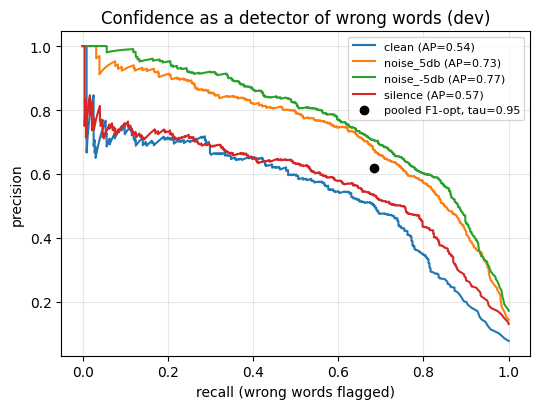

In [9]:
def word_labels(rs, modes=MODES):
    y, s, m = [], [], []
    for r in rs:
        gt = r["ground_truth"]
        for mode in modes:
            h = r["hyp"][mode]
            for j, (w, p, _, _) in enumerate(h["toks"]):
                gi = h["hyp_gt"][j]
                if gi is None:
                    continue
                y.append(int(w != gt[gi])); s.append(1 - p); m.append(mode)
    return np.array(y), np.array(s), np.array(m)

y, s, m = word_labels(dev)
prec, rec, thr = precision_recall_curve(y, s)
f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-9)
k = int(np.argmax(f1))
TAU = float(1 - thr[k] + 1e-6)                    # blank iff p < TAU
print(f"dev: {len(y)} aligned words, {y.mean():.1%} wrong | AP={average_precision_score(y, s):.3f} | "
      f"tau*={TAU:.3f} (P={prec[k]:.3f}, R={rec[k]:.3f}, F1={f1[k]:.3f})")

fig, ax = plt.subplots(figsize=(5.5, 4.2))
for mode in MODES:
    if y[m == mode].sum() == 0:
        continue
    pm, rm, _ = precision_recall_curve(y[m == mode], s[m == mode])
    ax.plot(rm, pm, label=f"{mode} (AP={average_precision_score(y[m == mode], s[m == mode]):.2f})")
ax.scatter([rec[k]], [prec[k]], c="k", zorder=5, label=f"pooled F1-opt, tau={TAU:.2f}")
ax.set_xlabel("recall (wrong words flagged)"); ax.set_ylabel("precision")
ax.set_title("Confidence as a detector of wrong words (dev)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("pr_curve.png", dpi=200); plt.show()

## 6. Masking rule and evaluation

**Deployable mask** (no ground truth): blank a word if `p < tau`; optionally insert a **gap blank** between two consecutive words if the timestamp gap exceeds `gap` seconds (Whisper dropped something). Ground-truth alignment is attached to each slot for scoring only.

**Systems**
| name | mask | emission |
|---|---|---|
| `whisper` | none | n/a |
| `lm_only` | deployable | flat |
| `full` | deployable | Whisper conf. + phonetic |
| `oracle_lm`, `oracle_full` | exactly the corrupted target word | flat / full |

The oracle rows isolate imputation quality from detection quality.

**Metrics**: WER of the final text; accuracy of the **target** (corrupted) word; blank-level top-1/top-5; blank precision (fraction of blanks that were truly wrong); recall of wrong words.

In [10]:
def gap_label(h, j):
    """ground-truth index for a gap blank inserted before hyp token j (None if ambiguous)"""
    g = h["hyp_gt"]
    prev = next((g[x] for x in range(j - 1, -1, -1) if g[x] is not None), -1)
    nxt = next((g[x] for x in range(j, len(g)) if g[x] is not None), 10**9)
    dels = [i for kind, i, _ in h["ops"] if kind == "del" and prev < i < nxt]
    return dels[0] if len(dels) == 1 else None


lex_set = set(lexicon)   # TIMIT lexicon: every true word is in it, so a hypothesis word outside it is certainly wrong

def make_slots(h, r, P):
    toks, slots = h["toks"], []
    if P["sys"] == "oracle":
        tgt = r["target_idx"]
        for kind, i, j in h["ops"]:
            if kind == "del":
                if i == tgt:
                    slots.append(Slot(None, None, i, True, True))
            else:
                slots.append(Slot(toks[j][0], toks[j][1], i, blank=(i == tgt)))
        return slots
    tau = P["tau"] if P["sys"] == "deploy" else -1.0
    gap = P["gap"] if P["sys"] == "deploy" else None
    for j, (w, p, st, en) in enumerate(toks):
        if gap is not None and j > 0 and st - toks[j - 1][3] > gap:
            slots.append(Slot(None, None, gap_label(h, j), True, True))
        is_blank = (p < tau) or (P["sys"] == "deploy" and P.get("lex_blank", False) and w not in lex_set)
        slots.append(Slot(w, p, h["hyp_gt"][j], blank=is_blank))
    return slots


def evaluate(rs, P, modes=MODES):
    rows, total = [], collections.Counter()
    for mode in modes:
        c = collections.Counter()
        for r in rs:
            gt, tgt, h = r["ground_truth"], r["target_idx"], r["hyp"][mode]
            slots = make_slots(h, r, P)
            final, preds = imp.fill(slots, P)
            c["edits"] += Lev.distance(gt, final); c["ref"] += len(gt)

            c["tgt_n"] += 1
            tk = next((k for k, s_ in enumerate(slots) if s_.gt == tgt), None)
            if tk is not None:
                if slots[tk].blank:
                    c["tgt_ok"] += vocab[preds[tk][0]] == gt[tgt]
                    c["tgt_top5"] += gt[tgt] in {vocab[x] for x in preds[tk]}
                else:
                    ok = slots[tk].word == gt[tgt]
                    c["tgt_ok"] += ok; c["tgt_top5"] += ok

            wrong_idx = {i for kind, i, _ in h["ops"] if kind in ("sub", "del")}
            blanked = set()
            for k, s_ in enumerate(slots):
                if not s_.blank:
                    continue
                c["blank_n"] += 1
                if s_.gt is None:
                    continue
                blanked.add(s_.gt); c["blank_lab"] += 1
                c["blank_wrong"] += bool(s_.gap or s_.word != gt[s_.gt])
                c["blank_top1"] += vocab[preds[k][0]] == gt[s_.gt]
                c["blank_top5"] += gt[s_.gt] in {vocab[x] for x in preds[k]}
            c["wrong_n"] += len(wrong_idx); c["wrong_blanked"] += len(wrong_idx & blanked)
        rows.append(_row(mode, c)); total += c
    rows.append(_row("all", total))
    return pd.DataFrame(rows)


def _row(name, c):
    d = lambda a, b: c[a] / max(c[b], 1)
    return dict(mode=name, WER=d("edits", "ref"), tgt_acc=d("tgt_ok", "tgt_n"), tgt_top5=d("tgt_top5", "tgt_n"),
                n_blanks=c["blank_n"], blank_top1=d("blank_top1", "blank_lab"), blank_top5=d("blank_top5", "blank_lab"),
                blank_prec=d("blank_wrong", "blank_lab"), wrong_recall=d("wrong_blanked", "wrong_n"))

BASE = dict(sys="deploy", tau=TAU, gap=None, kappa=1.0, gamma=4.0, emission=True, closed=CFG["closed_vocab"], lex_blank=True)
print(evaluate(dev, dict(BASE, sys="whisper")).round(3).to_string(index=False))

      mode   WER  tgt_acc  tgt_top5  n_blanks  blank_top1  blank_top5  blank_prec  wrong_recall
     clean 0.096    0.915     0.915         0         0.0         0.0         0.0           0.0
 noise_5db 0.172    0.435     0.435         0         0.0         0.0         0.0           0.0
noise_-5db 0.237    0.090     0.090         0         0.0         0.0         0.0           0.0
   silence 0.237    0.072     0.072         0         0.0         0.0         0.0           0.0
       all 0.185    0.378     0.378         0         0.0         0.0         0.0           0.0


## 7. Tune on dev (coordinate descent, objective = dev WER of the full model)

`(kappa, gamma)` first, then the gap threshold, then a small tau neighborhood around the PR-optimal value.

In [ ]:
def dev_wer(P):
    return float(evaluate(dev, P).query("mode == 'all'")["WER"].iloc[0])

best = dict(BASE); best_w = dev_wer(best); log = [(dict(best), best_w)]
print("start", round(best_w, 4))

for key, grid in [("lex_blank", [False, True]), ("kappa", [0.25, 0.5, 1.0, 2.0]), ("gamma", [1.0, 2.0, 4.0, 8.0]),
                  ("gap", [None, 0.15, 0.25, 0.4]), ("tau", [TAU * 0.6, TAU * 0.8, TAU, TAU * 1.2, min(TAU * 1.5, 0.95)])]:
    for v in grid:
        P = dict(best, **{key: v}); w = dev_wer(P); log.append((P, w))
        print(f"  {key}={v!r:>8}: WER={w:.4f}")
        if w < best_w:
            best, best_w = P, w
    print(f"-> {key} = {best[key]!r}  (dev WER {best_w:.4f})")

TUNED = best
print("TUNED:", TUNED)

start 0.184
  lex_blank=   False: WER=0.1854
  lex_blank=    True: WER=0.1840
-> lex_blank = True  (dev WER 0.1840)
  kappa=    0.25: WER=0.2114
  kappa=     0.5: WER=0.1996
  kappa=     1.0: WER=0.1840
  kappa=     2.0: WER=0.1749
-> kappa = 2.0  (dev WER 0.1749)
  gamma=     1.0: WER=0.1806
  gamma=     2.0: WER=0.1791
  gamma=     4.0: WER=0.1749
  gamma=     8.0: WER=0.1643
-> gamma = 8.0  (dev WER 0.1643)
  gap=    None: WER=0.1643
  gap=    0.15: WER=0.2472
  gap=    0.25: WER=0.1891
  gap=     0.4: WER=0.1722
-> gap = None  (dev WER 0.1643)
  tau=0.5671206: WER=0.1642
  tau=0.7561608000000001: WER=0.1642
  tau=0.9452010000000001: WER=0.1643


## 8. Final results on held-out test speakers

In [ ]:
SYSTEMS = {
    "whisper":     dict(TUNED, sys="whisper"),
    "lm_only":     dict(TUNED, emission=False),
    "full":        dict(TUNED),
    "oracle_lm":   dict(TUNED, sys="oracle", emission=False),
    "oracle_full": dict(TUNED, sys="oracle"),
}
res = {name: evaluate(test, P) for name, P in SYSTEMS.items()}
full_table = pd.concat({k: v.set_index("mode") for k, v in res.items()}, names=["system"])
full_table.to_csv("results_test.csv")

pd.set_option("display.width", 200)
print("WER (lower is better)")
print(pd.DataFrame({k: v.set_index("mode")["WER"] for k, v in res.items()}).round(4))
print("\nTarget-word accuracy (corrupted word recovered)")
print(pd.DataFrame({k: v.set_index("mode")["tgt_acc"] for k, v in res.items()}).round(3))
print("\nDetails for the full model")
print(res["full"].round(3).to_string(index=False))

## 9. Ablations (test speakers, full model)

Each row changes one thing relative to the tuned model.

In [ ]:
ablations = {
    "tuned (full)":              (TUNED, None),
    "no gap blanks":             (dict(TUNED, gap=None), None),
    "no lexicon blanks":         (dict(TUNED, lex_blank=False), None),
    "lexicon blanks only (tau=0)": (dict(TUNED, lex_blank=True, tau=0.0), None),
    "no phonetic sim (gamma=0)": (dict(TUNED, gamma=0.0), None),
    "open vocabulary":           (dict(TUNED, closed=False), None),
    "no Google prior (mu=0)":    (TUNED, 0.0),
    "heavy Google prior (mu=.5)":(TUNED, 0.5),
}
rows = []
for name, (P, mu) in ablations.items():
    if mu is not None:
        lm.set_mu(mu)
    r_ = evaluate(test, P).query("mode == 'all'").iloc[0]
    rows.append(dict(variant=name, WER=r_.WER, tgt_acc=r_.tgt_acc, blank_top1=r_.blank_top1, blank_top5=r_.blank_top5))
    lm.set_mu(CFG["mu_google"])
abl = pd.DataFrame(rows)
abl.to_csv("ablations_test.csv", index=False)
print(abl.round(4).to_string(index=False))

## 10. Part 3: soft full-chain HMM with MLE-learned emission

Part 2 makes a hard decision (blank or keep), so a confident wrong word can never be corrected. Here **every** position is a hidden word `W_t` and the whole sentence is scored by forward-backward:

`P(W_t | all A) ∝ alpha_t(w) * beta_t(w)`, with emission `e_t(w) = P(A_t | w)`:
* `e_t(d) = p~` for the decoded word `d`, and `e_t(w) = (1 - p~) * q(w | d)` otherwise, with `q(w | d) ∝ exp(-gamma * phone_dist(w, d))`; the whole term is raised to `kappa`.
* A decoded word outside the lexicon (a CTC non-word) gets `e_t(d) = 0` automatically, so it is always replaced by the best-fitting lexicon word.
* A gap slot (Whisper/CTC dropped a word) has a flat emission, as before.

Decoding is posterior (marginal) decoding: the most probable word at each position, which minimises the expected number of word errors.

**Emission parameters learned by maximum likelihood on the labelled dev split**
1. `p~ = calib(p)`: isotonic regression of "decoded word is correct" on the raw confidence (a monotone, constrained Bernoulli MLE). This corrects overconfident confidences such as CTC posteriors.
2. `gamma`: maximises `sum log q(true | heard)` over dev substitution pairs, replacing the grid search.

**Exactness:** emissions are zero outside the TIMIT lexicon, so the chain can be restricted to those ~6k words without approximation (`S`, `lambda`, `p_low` are only sliced). Cell 10b checks this against the full-vocabulary pass.


In [ ]:
class LexChain:
    """Exact forward-backward restricted to the closed vocabulary (the TIMIT lexicon).
    Emissions vanish outside the lexicon, so slicing S, lambda and p_low to it is exact, and
    every message lives on ~6k words instead of the full ~50k LM vocabulary."""
    def __init__(self, lm, vocab, index, lexicon_ids):
        self.ids = np.asarray(lexicon_ids)
        self.L = len(self.ids)
        self.words = [vocab[i] for i in self.ids]
        self.word_pos = {w: k for k, w in enumerate(self.words)}
        self.S = lm.S[self.ids][:, self.ids].tocsr()
        self.St = self.S.T.tocsr()
        self.lam = lm.lam[self.ids]
        self.p_low = lm.p_low[self.ids]
        self.left_bos = lm.row(BOS)[self.ids]        # P(w | <s>)
        self.col_eos = lm.col(EOS)[self.ids]         # P(</s> | v)
        self.prons = [pron_string(w) or "" for w in self.words]
        self._cache = {}

    def ndist(self, d):
        """normalized phoneme (or spelling) edit distance from decoded word d to every lexicon word"""
        hit = self._cache.get(d)
        if hit is not None:
            return hit
        ps = pron_string(d)
        if ps is not None:
            dist = rf_process.cdist([ps], self.prons, scorer=Lev.normalized_distance, dtype=np.float32)[0]
        else:
            dist = rf_process.cdist([d], self.words, scorer=Lev.normalized_distance, dtype=np.float32)[0]
        if len(self._cache) > 5000:
            self._cache.pop(next(iter(self._cache)))
        self._cache[d] = dist
        return dist

    def emission(self, word, p, kappa, gamma):
        """e[w] = P(A | w) over the lexicon. word=None -> flat (gap slot)"""
        if word is None:
            return np.ones(self.L)
        p = min(max(p, 1e-3), 1 - 1e-3)
        q = np.exp(-gamma * self.ndist(word)).astype(np.float64)
        di = self.word_pos.get(word)
        if di is not None:
            q[di] = 0.0
        q /= q.sum()
        e = (1 - p) * q
        if di is not None:
            e[di] = p
        return np.maximum(e, 1e-12) ** kappa

    def posteriors(self, ems):
        n = len(ems)
        alpha, beta = [None] * n, [None] * n
        a = self.left_bos * ems[0]
        alpha[0] = a / a.sum()
        for k in range(1, n):
            prev = alpha[k - 1]
            a = (self.St @ prev + (prev @ self.lam) * self.p_low) * ems[k]
            alpha[k] = a / a.sum()
        b = self.col_eos
        beta[n - 1] = b / b.sum()
        for k in range(n - 2, -1, -1):
            x = ems[k + 1] * beta[k + 1]
            b = self.S @ x + self.lam * (self.p_low @ x)
            beta[k] = b / b.sum()
        out = []
        for k in range(n):
            post = alpha[k] * beta[k]
            s = post.sum()
            out.append(post / s if s > 0 else ems[k] / ems[k].sum())
        return out


def fill_soft(chain, slots, P):
    """every slot is a hidden word. returns (final words, top-5 lexicon words per slot)"""
    if not slots:
        return [], []
    cal = P.get("calib")
    ems = []
    for s_ in slots:
        if s_.gap:
            ems.append(chain.emission(None, None, 1.0, 0.0))
        else:
            p = cal(s_.p) if cal is not None else s_.p
            ems.append(chain.emission(s_.word, p, P["kappa"], P["gamma"]))
    final, preds = [], []
    for post in chain.posteriors(ems):
        top = np.argpartition(-post, 5)[:5]
        top = top[np.argsort(-post[top])]
        preds.append([chain.words[i] for i in top])
        final.append(chain.words[top[0]])
    return final, preds


def evaluate_soft(rs, P, modes=MODES, chain=None):
    chain = chain or CHAIN
    rows, total = [], collections.Counter()
    for mode in modes:
        c = collections.Counter()
        for r in rs:
            gt, tgt, h = r["ground_truth"], r["target_idx"], r["hyp"][mode]
            slots = make_slots(h, r, P)                 # P has tau=-1, lex_blank=False: slots only carry word/p/gap
            final, preds = fill_soft(chain, slots, P)
            c["edits"] += Lev.distance(gt, final); c["ref"] += len(gt)
            c["tgt_n"] += 1
            tk = next((k for k, s_ in enumerate(slots) if s_.gt == tgt), None)
            if tk is not None:
                c["tgt_ok"] += final[tk] == gt[tgt]
                c["tgt_top5"] += gt[tgt] in preds[tk]
            for k, s_ in enumerate(slots):
                if s_.gap or s_.gt is None:
                    continue
                was, now = s_.word == gt[s_.gt], final[k] == gt[s_.gt]
                c["words"] += 1; c["wrong_before"] += (not was)
                c["fixed"] += (not was) and now
                c["broken"] += was and (not now)
        rows.append(_row_soft(mode, c)); total += c
    rows.append(_row_soft("all", total))
    return pd.DataFrame(rows)


def _row_soft(name, c):
    d = lambda a, b: c[a] / max(c[b], 1)
    return dict(mode=name, WER=d("edits", "ref"), tgt_acc=d("tgt_ok", "tgt_n"), tgt_top5=d("tgt_top5", "tgt_n"),
                wrong_before=c["wrong_before"], fixed=c["fixed"], broken=c["broken"], net=c["fixed"] - c["broken"])


CHAIN = LexChain(lm, vocab, index, lexicon_ids)
print(f"closed-vocabulary chain: {CHAIN.L} words, {CHAIN.S.nnz:,} stored bigram entries")


In [ ]:
# 10b. sanity check: the restricted chain must equal exact full-vocabulary forward-backward (closed vocab)
P_chk = dict(sys="deploy", tau=-1.0, gap=None, lex_blank=False)
r0 = next(r for r in dev if len(r["hyp"]["noise_-5db"]["toks"]) >= 3)
slots = make_slots(r0["hyp"]["noise_-5db"], r0, P_chk)
ems_full = [imp.emission(s_, 1.0, 4.0, imp.mask_closed) for s_ in slots]
post_full = impute_segment(lm, BOS, EOS, ems_full)
post_L = CHAIN.posteriors([CHAIN.emission(s_.word, s_.p, 1.0, 4.0) for s_ in slots])
err = max(np.abs(a[CHAIN.ids] - b).max() for a, b in zip(post_full, post_L))
print(f"max |full-vocab posterior - restricted posterior| = {err:.2e}  (should be ~1e-12)")


In [ ]:
# 10c. learn the emission parameters by MLE on the labelled dev split
from sklearn.isotonic import IsotonicRegression

def collect_pairs(rs, modes=MODES):
    P_, H_, T_ = [], [], []
    for r in rs:
        gt = r["ground_truth"]
        for mode in modes:
            h = r["hyp"][mode]
            for j, (w, p, _, _) in enumerate(h["toks"]):
                gi = h["hyp_gt"][j]
                if gi is None:
                    continue
                P_.append(p); H_.append(w); T_.append(gt[gi])
    return np.array(P_), H_, T_

dev_p, dev_heard, dev_true = collect_pairs(dev)
in_lex = np.array([w in lex_set for w in dev_heard])
right = np.array([h == t for h, t in zip(dev_heard, dev_true)])
print(f"dev aligned words: {len(right)} | in lexicon: {in_lex.mean():.1%} | correct: {right.mean():.1%} "
      f"| correct among in-lexicon words: {right[in_lex].mean():.1%}")

# (1) confidence calibration: isotonic regression = monotone Bernoulli MLE. Non-lexicon words are
#     excluded because the lexicon already rules them out (their emission is 0).
iso = IsotonicRegression(y_min=0.01, y_max=0.99, increasing=True, out_of_bounds="clip")
iso.fit(dev_p[in_lex], right[in_lex].astype(float))
_g = np.linspace(0, 1, 401); _c = iso.predict(_g)
CALIB = lambda p: float(np.interp(p, _g, _c))

edges = [0, .2, .4, .6, .8, .9, .95, .99, 1.0001]
rows = []
for lo, hi in zip(edges[:-1], edges[1:]):
    m_ = in_lex & (dev_p >= lo) & (dev_p < hi)
    if m_.sum():
        rows.append(dict(raw_p=f"[{lo:.2f},{min(hi,1):.2f})", n=int(m_.sum()), empirical_correct=right[m_].mean(),
                         mean_raw_p=dev_p[m_].mean(), calibrated=np.mean([CALIB(x) for x in dev_p[m_]])))
print(pd.DataFrame(rows).round(3).to_string(index=False))

# (2) confusion sharpness gamma: maximise sum log q(true | heard) over dev substitution pairs
def fit_gamma(chain, heard, true, grid=(0.5, 1, 2, 3, 4, 6, 8, 12, 16), max_pairs=2000):
    pairs = [(d, w) for d, w in zip(heard, true) if d != w and w in chain.word_pos]
    random.Random(0).shuffle(pairs); pairs = pairs[:max_pairs]
    ll = np.zeros(len(grid))
    for d, w in pairs:
        dist = chain.ndist(d).astype(np.float64)
        di, wi = chain.word_pos.get(d), chain.word_pos[w]
        for gi, g in enumerate(grid):
            z = np.exp(-g * dist)
            if di is not None:
                z[di] = 0.0
            ll[gi] += -g * dist[wi] - np.log(z.sum())
    return grid[int(np.argmax(ll))], {g: round(float(v) / len(pairs), 4) for g, v in zip(grid, ll)}, len(pairs)

GAMMA_HAT, ll_by_gamma, n_pairs = fit_gamma(CHAIN, dev_heard, dev_true)
print(f"\nMLE gamma = {GAMMA_HAT} from {n_pairs} substitution pairs; mean log q(true|heard) by gamma:")
print(ll_by_gamma)


In [ ]:
# 10d. tune the two remaining knobs (kappa, gap) on a dev subsample; parameters above stay fixed
DEV_SUB = 300                                   # raise for a slower, more precise search
dev_small = dev[::max(1, len(dev) // DEV_SUB)]
SOFT = dict(sys="deploy", tau=-1.0, gap=None, lex_blank=False, kappa=1.0, gamma=GAMMA_HAT, calib=CALIB)

def dev_wer_soft(P):
    return float(evaluate_soft(dev_small, P).query("mode == 'all'")["WER"].iloc[0])

best_soft = dict(SOFT); best_sw = dev_wer_soft(best_soft)
print("start (kappa=1, calibrated p, MLE gamma):", round(best_sw, 4))
for key, grid in [("kappa", [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]), ("gap", [None, 0.4, 0.6, 0.8])]:
    for v in grid:
        w = dev_wer_soft(dict(best_soft, **{key: v}))
        print(f"  {key}={v!r:>5}: WER={w:.4f}")
        if w < best_sw:
            best_soft, best_sw = dict(best_soft, **{key: v}), w
    print(f"-> {key} = {best_soft[key]!r}  (dev WER {best_sw:.4f})")
TUNED_SOFT = best_soft
print({k: v for k, v in TUNED_SOFT.items() if k != "calib"})


In [ ]:
# 10e. held-out test speakers: baseline vs hard-blank model vs soft full-chain model (+ ablations)
if "res" not in globals():
    res = {n: evaluate(test, P) for n, P in SYSTEMS.items()}

SOFT_SYS = {
    "soft HMM (calibrated, MLE gamma)": TUNED_SOFT,
    "  no calibration (raw p)":        dict(TUNED_SOFT, calib=None),
    "  gamma=4 (not learned)":         dict(TUNED_SOFT, gamma=4.0),
    "  kappa=1":                       dict(TUNED_SOFT, kappa=1.0),
}
res_soft = {k: evaluate_soft(test, P) for k, P in SOFT_SYS.items()}

col = lambda df, c: df.set_index("mode")[c]
wer = pd.DataFrame({"baseline ASR": col(res["whisper"], "WER"), "hard-blank full": col(res["full"], "WER"),
                    **{k: col(v, "WER") for k, v in res_soft.items()}})
acc = pd.DataFrame({"baseline ASR": col(res["whisper"], "tgt_acc"), "hard-blank full": col(res["full"], "tgt_acc"),
                    **{k: col(v, "tgt_acc") for k, v in res_soft.items()}})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
print("WER (lower is better)"); print(wer.round(4).to_string())
print("\nTarget-word accuracy (corrupted word recovered)"); print(acc.round(3).to_string())
print("\nSoft HMM: words fixed vs broken relative to the decoded text")
print(res_soft["soft HMM (calibrated, MLE gamma)"].round(4).to_string(index=False))

pd.concat({k: v.set_index("mode") for k, v in res_soft.items()}, names=["system"]).to_csv("results_soft_test.csv")
wer.to_csv("wer_soft_test.csv"); acc.to_csv("tgt_acc_soft_test.csv")


## 11. Error detector as a Bayesian network: MLE vs EM (items B and D)

Let `E_t` = "decoded word t is wrong". The evidence for each decoded word is three discrete variables:
`C` = confidence bin, `F` = LM-fit bin (`log P(w | left) + log P(right | w)` from the bigram LM on the *decoded* neighbours), `X` = outside the TIMIT lexicon.

Three structures are compared:
1. **Naive Bayes** `E -> C, F, X`, learned by MLE (Laplace smoothing) from the labelled dev alignment.
2. **CPT** `C, F, X -> E`, learned by MLE (counts shrunk toward the global error rate).
3. **Latent naive Bayes**, the same graph as (1) but `E` is never observed: parameters are learned by **EM** on unlabelled dev tokens (E-step: posterior of `E`; M-step: expected counts). The log-likelihood is monotone, which gives the convergence trace. The labels are used only afterwards, to score the detector.

Each detector gives `P(E_t = 1 | evidence)`. It is scored by average precision against the true labels on the test speakers, then used as the blanking rule of the hard-blank pipeline (blank iff `P(wrong) > t`, with `t` picked on dev) and compared with the single-threshold `tau` rule.


In [ ]:
# 11a. features + the three network structures
FEAT_CACHE = {}

def token_features(toks):
    """per decoded token: (confidence, LM fit with decoded neighbours, in-lexicon flag)"""
    hit = FEAT_CACHE.get(id(toks))
    if hit is not None:
        return hit
    ids = [index.get(t[0], UNK) for t in toks]
    out = []
    for j, (w, p, _, _) in enumerate(toks):
        l = ids[j - 1] if j > 0 else BOS
        r = ids[j + 1] if j + 1 < len(toks) else EOS
        if ids[j] == UNK:
            fit = -30.0
        else:
            fit = float(np.log(max(lm.row(l)[ids[j]], 1e-12)) + np.log(max(lm.row(ids[j])[r], 1e-12)))
        out.append((p, fit, w in lex_set))
    FEAT_CACHE[id(toks)] = out
    return out


def collect_feats(rs, modes=MODES):
    F_, y_ = [], []
    for r in rs:
        gt = r["ground_truth"]
        for m in modes:
            h = r["hyp"][m]
            for j, f in enumerate(token_features(h["toks"])):
                gi = h["hyp_gt"][j]
                if gi is None:
                    continue
                F_.append(f); y_.append(int(h["toks"][j][0] != gt[gi]))
    return F_, np.array(y_)


class ErrorBN:
    A = 1.0                                                         # Laplace / Dirichlet smoothing

    def __init__(self, n_bins=6):
        self.nb = n_bins

    def fit_bins(self, feats):
        p = np.array([f[0] for f in feats]); fit = np.array([f[1] for f in feats])
        qs = np.linspace(0, 1, self.nb + 1)[1:-1]
        self.ec, self.ef = np.unique(np.quantile(p, qs)), np.unique(np.quantile(fit, qs))
        self.nc, self.nf = len(self.ec) + 1, len(self.ef) + 1
        return self

    def codes(self, feats):
        p = np.array([f[0] for f in feats]); fit = np.array([f[1] for f in feats])
        x = np.array([int(not f[2]) for f in feats], dtype=int)
        return np.digitize(p, self.ec), np.digitize(fit, self.ef), x

    # ---- structure 1 / 3: E -> C, F, X (naive Bayes) -------------------------------------------
    def _set_naive(self, c, f, x, r):
        """M-step / MLE from (soft) responsibilities r = P(E=1)."""
        a = self.A
        w = np.stack([1 - r, r])                                   # weights for E=0, E=1
        self.pi1 = (r.sum() + a) / (len(r) + 2 * a)
        tab = lambda v, n: np.stack([(np.bincount(v, weights=w[e], minlength=n) + a) / (w[e].sum() + a * n)
                                     for e in (0, 1)])
        self.Pc, self.Pf, self.Px = tab(c, self.nc), tab(f, self.nf), tab(x, 2)

    def _naive_post(self, c, f, x):
        lo = (np.log(self.pi1 / (1 - self.pi1)) + np.log(self.Pc[1][c] / self.Pc[0][c])
              + np.log(self.Pf[1][f] / self.Pf[0][f]) + np.log(self.Px[1][x] / self.Px[0][x]))
        return 1 / (1 + np.exp(-lo))

    def fit_naive(self, feats, y):
        c, f, x = self.codes(feats); self.kind = "naive"
        self._set_naive(c, f, x, y.astype(float))
        return self

    # ---- structure 3: same graph, E latent, learned by EM --------------------------------------
    def fit_em(self, feats, n_iter=300, tol=1e-8):
        c, f, x = self.codes(feats); self.kind = "naive"
        p = np.array([ft[0] for ft in feats])
        r = np.clip(1 - p, 0.02, 0.98); r[x == 1] = 0.98           # heuristic initial responsibilities
        self.trace = []
        for it in range(n_iter):
            self._set_naive(c, f, x, r)                             # M-step
            l1 = np.log(self.pi1) + np.log(self.Pc[1][c]) + np.log(self.Pf[1][f]) + np.log(self.Px[1][x])
            l0 = np.log(1 - self.pi1) + np.log(self.Pc[0][c]) + np.log(self.Pf[0][f]) + np.log(self.Px[0][x])
            m = np.maximum(l1, l0)
            ll = np.sum(m + np.log(np.exp(l1 - m) + np.exp(l0 - m)))
            prior = self.A * (np.log(self.pi1) + np.log(1 - self.pi1) + np.log(self.Pc).sum()
                              + np.log(self.Pf).sum() + np.log(self.Px).sum())
            self.trace.append(float((ll + prior) / len(c)))           # penalised (MAP) objective: monotone under EM
            r = 1 / (1 + np.exp(l0 - l1))                           # E-step
            if it > 0 and abs(self.trace[-1] - self.trace[-2]) < tol:
                break
        return self

    # ---- structure 2: C, F, X -> E (CPT) ---------------------------------------------------------
    def fit_cpt(self, feats, y, strength=2.0):
        c, f, x = self.codes(feats); self.kind = "cpt"
        n = np.zeros((self.nc, self.nf, 2)); w = np.zeros_like(n)
        np.add.at(n, (c, f, x), 1); np.add.at(w, (c, f, x), y)
        self.T = (w + strength * y.mean()) / (n + strength)
        return self

    def prob_wrong(self, feats):
        if not len(feats):
            return np.zeros(0)
        c, f, x = self.codes(feats)
        return self.T[c, f, x] if self.kind == "cpt" else self._naive_post(c, f, x)


In [ ]:
# 11b. fit on dev (labels used only for the two supervised structures) and score on test speakers
from sklearn.metrics import roc_auc_score
Fdev, ydev = collect_feats(dev); Ftest, ytest = collect_feats(test)
print(f"dev tokens {len(ydev)} ({ydev.mean():.1%} wrong) | test tokens {len(ytest)} ({ytest.mean():.1%} wrong)")

bn_nb  = ErrorBN().fit_bins(Fdev).fit_naive(Fdev, ydev)
bn_cpt = ErrorBN().fit_bins(Fdev).fit_cpt(Fdev, ydev)
bn_em  = ErrorBN().fit_bins(Fdev).fit_em(Fdev)                    # no labels
DET = {"supervised CPT  (C,F,X -> E)": bn_cpt, "supervised naive Bayes (E -> C,F,X)": bn_nb,
       "latent naive Bayes, EM (no labels)": bn_em}

rows = [dict(detector="raw confidence (1 - p)", AP=average_precision_score(ytest, [1 - f[0] for f in Ftest]),
             AUC=roc_auc_score(ytest, [1 - f[0] for f in Ftest]))]
for name, mdl in DET.items():
    s_ = mdl.prob_wrong(Ftest)
    rows.append(dict(detector=name, AP=average_precision_score(ytest, s_), AUC=roc_auc_score(ytest, s_)))
print(f"\nwrong-word detection on test speakers (base rate {ytest.mean():.3f})")
print(pd.DataFrame(rows).round(3).to_string(index=False))

tr = bn_em.trace
print(f"\nEM: {len(tr)} iterations, avg penalised log-likelihood {tr[0]:.4f} -> {tr[-1]:.4f}, monotone: {bool(np.all(np.diff(tr) > -1e-9))}")
print(f"EM estimate of P(wrong) = {bn_em.pi1:.3f} (true dev rate {ydev.mean():.3f}) | "
      f"P(outside lexicon | wrong) = {bn_em.Px[1][1]:.3f} vs P(outside lexicon | right) = {bn_em.Px[0][1]:.3f}")
plt.figure(figsize=(4.5, 3.2)); plt.plot(tr); plt.xlabel("EM iteration"); plt.ylabel("avg penalised log-lik")
plt.title("Latent error variable: EM convergence"); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("em_convergence.png", dpi=200); plt.show()


In [ ]:
# 11c. use each detector as the blanking rule of the hard-blank pipeline
if "_make_slots_base" not in globals():
    _make_slots_base = make_slots

def make_slots(h, r, P):
    if P.get("bn") is None or P["sys"] != "deploy":
        return _make_slots_base(h, r, P)
    slots = _make_slots_base(h, r, dict(P, tau=-1.0, lex_blank=False))   # slots only, no blanks yet
    wrong = P["bn"](h["toks"])                                           # P(wrong) per decoded token
    j = 0
    for s_ in slots:
        if not s_.gap:
            s_.blank = bool(wrong[j] > P["bn_t"]); j += 1
    return slots

bn_fn = lambda mdl: (lambda toks: mdl.prob_wrong(token_features(toks)))
dev_small2 = dev[::max(1, len(dev) // 200)]
pick = {}
for name, mdl in DET.items():
    best_t, best_w = None, 9.0
    for t in [0.2, 0.35, 0.5, 0.65, 0.8]:
        w = float(evaluate(dev_small2, dict(TUNED, bn=bn_fn(mdl), bn_t=t)).query("mode == 'all'")["WER"].iloc[0])
        if w < best_w:
            best_t, best_w = t, w
    pick[name] = best_t
    print(f"{name}: best blank threshold t={best_t} (dev WER {best_w:.4f})")

if "res" not in globals():
    res = {n: evaluate(test, P) for n, P in SYSTEMS.items()}
rows = []
r_ = res["full"].query("mode == 'all'").iloc[0]
rows.append(dict(blanking_rule="tau + lexicon rule (Part 2)", WER=r_.WER, tgt_acc=r_.tgt_acc, n_blanks=r_.n_blanks,
                 blank_prec=r_.blank_prec, wrong_recall=r_.wrong_recall))
for name, mdl in DET.items():
    r_ = evaluate(test, dict(TUNED, bn=bn_fn(mdl), bn_t=pick[name])).query("mode == 'all'").iloc[0]
    rows.append(dict(blanking_rule=name, WER=r_.WER, tgt_acc=r_.tgt_acc, n_blanks=r_.n_blanks,
                     blank_prec=r_.blank_prec, wrong_recall=r_.wrong_recall))
bn_tab = pd.DataFrame(rows)
print("\nHard-blank pipeline on test speakers (all modes pooled)")
print(bn_tab.round(4).to_string(index=False)); bn_tab.to_csv("bn_detector_test.csv", index=False)


## 12. Multi-word corruption: does exact inference beat greedy decoding? (item C)

`phase1_multi_ctc.py` corrupts **K adjacent words** per utterance (K = 2, 3). Adjacent unreliable words are exactly where the chain structure should matter: the second word's best value depends on the first word's *distribution*, not on a committed guess.

All four decoders use the same soft-HMM emissions (calibrated confidence, MLE `gamma`, tuned `kappa`) and the same bigram LM, and differ only in how they read the chain:

| decoder | what it computes |
|---|---|
| no LM | the recognizer output as is |
| greedy L->R | commits to the best word at each position given the previous *committed* word, no look-ahead |
| posterior (fwd-bwd) | per-position marginals `P(W_t | all evidence)`, minimises expected word errors |
| Viterbi (MAP) | the single most probable word sequence (max-product) |

Viterbi uses the same sparse-plus-rank-1 structure as forward-backward (`max_v delta(v) * (S[v,w] + lambda(v) p_low(w))` is the max of a sparse part and a rank-1 part), so it also runs without a dense `V x V` matrix. Cell 12b checks it against a brute-force dense version.


In [ ]:
# 12a. decoders on the lexicon chain
class ChainViterbi:
    """exact max-product (Viterbi) on the restricted chain, using S + rank-1 structure (no dense matrix)"""
    def __init__(self, chain):
        self.c = chain
        S = chain.S.tocsc(); S.sort_indices()
        L = chain.L
        self.rows, counts = S.indices, np.diff(S.indptr)
        self.cols = np.repeat(np.arange(L), counts)
        self.logSp = np.log(S.data + chain.lam[self.rows] * chain.p_low[self.cols])
        self.nonempty = counts > 0
        self.starts = S.indptr[:-1][self.nonempty]
        self.loglam, self.logplow = np.log(chain.lam), np.log(chain.p_low)

    def step(self, delta):
        L = self.c.L
        vals = delta[self.rows] + self.logSp
        colmax = np.full(L, -np.inf)
        arg = np.zeros(L, dtype=np.int64)
        if vals.size:
            colmax[self.nonempty] = np.maximum.reduceat(vals, self.starts)
            hit = np.flatnonzero(vals == colmax[self.cols])
            cols_hit, first = np.unique(self.cols[hit], return_index=True)
            arg[cols_hit] = self.rows[hit[first]]
        g = delta + self.loglam
        vstar = int(g.argmax())
        r1 = g[vstar] + self.logplow                      # best "back-off" predecessor for every w
        use = r1 > colmax
        return np.where(use, r1, colmax), np.where(use, vstar, arg)

    def decode(self, ems):
        c, n = self.c, len(ems)
        le = [np.log(e) for e in ems]
        delta = np.log(c.left_bos) + le[0]
        back = []
        for k in range(1, n):
            best, arg = self.step(delta)
            delta = best + le[k]; back.append(arg)
        delta = delta + np.log(c.col_eos)
        path = [int(delta.argmax())]
        for arg in reversed(back):
            path.append(int(arg[path[-1]]))
        return path[::-1]


def row_L(chain, w):
    """P(. | w) restricted to the lexicon"""
    r = chain.lam[w] * chain.p_low
    a, b = chain.S.indptr[w], chain.S.indptr[w + 1]
    r[chain.S.indices[a:b]] += chain.S.data[a:b]
    return r

def decode_greedy(chain, ems):
    out, row = [], chain.left_bos
    for e in ems:
        w = int((row * e).argmax()); out.append(w); row = row_L(chain, w)
    return out

def slot_ems(chain, slots, P):
    cal, ems = P.get("calib"), []
    for s_ in slots:
        if s_.gap:
            ems.append(chain.emission(None, None, 1.0, 0.0))
        else:
            ems.append(chain.emission(s_.word, cal(s_.p) if cal else s_.p, P["kappa"], P["gamma"]))
    return ems

VIT = ChainViterbi(CHAIN)
print("Viterbi decoder ready:", f"{len(VIT.rows):,} sparse transitions")


In [ ]:
# 12b. check Viterbi against brute force (dense max-product) on a real sentence
r0 = next(r for r in dev if len(r["hyp"]["noise_-5db"]["toks"]) >= 4)
slots = make_slots(r0["hyp"]["noise_-5db"], r0, dict(sys="deploy", tau=-1.0, gap=None, lex_blank=False))
ems = slot_ems(CHAIN, slots, TUNED_SOFT)
L = CHAIN.L
T = CHAIN.S.astype(np.float32).toarray()
for i in range(0, L, 1000):
    T[i:i + 1000] += (CHAIN.lam[i:i + 1000, None] * CHAIN.p_low[None, :]).astype(np.float32)
logT = np.log(T); del T
delta = np.log(CHAIN.left_bos) + np.log(ems[0]); back = []
for k in range(1, len(ems)):
    M = delta[:, None] + logT
    back.append(M.argmax(0)); delta = M.max(0) + np.log(ems[k])
delta = delta + np.log(CHAIN.col_eos)
path = [int(delta.argmax())]
for bp in reversed(back):
    path.append(int(bp[path[-1]]))
brute = path[::-1]; del logT
print("Viterbi == brute-force dense max-product:", VIT.decode(ems) == brute)


In [ ]:
# 12c. evaluate on the multi-word-corruption runs (test speakers only, parameters from Part 3)
def load_multi(path):
    out = []
    for r in json.load(open(path)):
        if os.path.basename(r["utterance_id"]).upper().startswith("SA") or speaker_of(r["utterance_id"]) in dev_spk:
            continue
        r["ground_truth"] = [w.lower() for w in r["ground_truth"]]
        r["hyp"] = {m: prep_hyp(r["runs"][m], r["ground_truth"]) for m in r["runs"]}
        out.append(r)
    return out

DEC = ["no LM (decoded)", "greedy L->R", "posterior (fwd-bwd)", "Viterbi (MAP)"]

def evaluate_multi(rs, P, chain=None, vit=None):
    chain, vit = chain or CHAIN, vit or VIT
    P0 = dict(sys="deploy", tau=-1.0, gap=None, lex_blank=False)
    rows = []
    for mode in sorted({m for r in rs for m in r["hyp"]}):
        c = {d: collections.Counter() for d in DEC}
        for r in rs:
            gt, tg, h = r["ground_truth"], r["target_idxs"], r["hyp"][mode]
            slots = make_slots(h, r, P0)
            fin = {"no LM (decoded)": [s_.word for s_ in slots]}
            if slots:
                ems = slot_ems(chain, slots, P)
                fin["posterior (fwd-bwd)"] = [chain.words[int(np.argmax(q))] for q in chain.posteriors(ems)]
                fin["greedy L->R"] = [chain.words[i] for i in decode_greedy(chain, ems)]
                fin["Viterbi (MAP)"] = [chain.words[i] for i in vit.decode(ems)]
            else:
                fin = {d: [] for d in DEC}
            tks = [next((k for k, s_ in enumerate(slots) if s_.gt == i), None) for i in tg]
            for d in DEC:
                c[d]["edits"] += Lev.distance(gt, fin[d]); c[d]["ref"] += len(gt)
                ok = [tk is not None and fin[d][tk] == gt[i] for tk, i in zip(tks, tg)]
                c[d]["tw"] += sum(ok); c[d]["tn"] += len(ok); c[d]["all_ok"] += all(ok); c[d]["utt"] += 1
        for d in DEC:
            x = c[d]
            rows.append(dict(mode=mode, decoder=d, WER=x["edits"] / max(x["ref"], 1), target_word_acc=x["tw"] / max(x["tn"], 1),
                             all_targets_correct=x["all_ok"] / max(x["utt"], 1)))
    return pd.DataFrame(rows)

MULTI_FILES = {2: "phase1_ctc_k2.json", 3: "phase1_ctc_k3.json"}
multi_res = {}
for k, path in MULTI_FILES.items():
    if not os.path.exists(path):
        print(f"k={k}: {path} not found (run phase1_multi_ctc.py --k {k})"); continue
    rs = load_multi(path)
    multi_res[k] = evaluate_multi(rs, TUNED_SOFT)
    print(f"\n=== k={k} adjacent corrupted words | {len(rs)} test utterances ===")
    for metric in ["WER", "target_word_acc", "all_targets_correct"]:
        print(f"\n{metric}"); print(multi_res[k].pivot(index="mode", columns="decoder", values=metric)[DEC].round(4).to_string())
if multi_res:
    pd.concat(multi_res, names=["k"]).to_csv("multi_word_results.csv")
